In [1]:
import pandas as pd
df = pd.read_csv("diabetes_data_upload.csv")

In [2]:
df.shape

(520, 17)

In [3]:
df.head()

,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes,Positive
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No,Positive
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No,Positive
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No,Positive
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Positive


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Age                 520 non-null    int64 
 1   Gender              520 non-null    object
 2   Polyuria            520 non-null    object
 3   Polydipsia          520 non-null    object
 4   sudden weight loss  520 non-null    object
 5   weakness            520 non-null    object
 6   Polyphagia          520 non-null    object
 7   Genital thrush      520 non-null    object
 8   visual blurring     520 non-null    object
 9   Itching             520 non-null    object
 10  Irritability        520 non-null    object
 11  delayed healing     520 non-null    object
 12  partial paresis     520 non-null    object
 13  muscle stiffness    520 non-null    object
 14  Alopecia            520 non-null    object
 15  Obesity             520 non-null    object
 16  class               520 no

In [5]:
df.isnull().sum()

Age                   0
Gender                0
Polyuria              0
Polydipsia            0
sudden weight loss    0
weakness              0
Polyphagia            0
Genital thrush        0
visual blurring       0
Itching               0
Irritability          0
delayed healing       0
partial paresis       0
muscle stiffness      0
Alopecia              0
Obesity               0
class                 0
dtype: int64

In [6]:
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

print(X.shape, y.shape, y.name)

(520, 16) (520,) class


In [7]:
y.unique().tolist()

['Positive', 'Negative']

In [8]:
y.value_counts()

class
Positive    320
Negative    200
Name: count, dtype: int64

In [9]:
X.columns.tolist()

['Age',
 'Gender',
 'Polyuria',
 'Polydipsia',
 'sudden weight loss',
 'weakness',
 'Polyphagia',
 'Genital thrush',
 'visual blurring',
 'Itching',
 'Irritability',
 'delayed healing',
 'partial paresis',
 'muscle stiffness',
 'Alopecia',
 'Obesity']

In [10]:
for column in X.select_dtypes(include=["object", "string"]).columns:
    print(column, X[column].unique().tolist())

Gender ['Male', 'Female']
Polyuria ['No', 'Yes']
Polydipsia ['Yes', 'No']
sudden weight loss ['No', 'Yes']
weakness ['Yes', 'No']
Polyphagia ['No', 'Yes']
Genital thrush ['No', 'Yes']
visual blurring ['No', 'Yes']
Itching ['Yes', 'No']
Irritability ['No', 'Yes']
delayed healing ['Yes', 'No']
partial paresis ['No', 'Yes']
muscle stiffness ['Yes', 'No']
Alopecia ['Yes', 'No']
Obesity ['Yes', 'No']


In [11]:
X["Polyuria"].map({"Yes": 1, "No": 0}).head()

0    0
1    0
2    1
3    0
4    1
Name: Polyuria, dtype: int64

In [12]:
X_encoded = X.copy()
symptom_columns = X.columns.drop(["Age", "Gender"])

for column in symptom_columns:
    X_encoded[column] = X[column].map({"Yes": 1, "No": 0})

X_encoded.head()

,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity
0,40,Male,0,1,0,1,0,0,0,1,0,1,0,1,1,1
1,58,Male,0,0,0,1,0,0,1,0,0,0,1,0,1,0
2,41,Male,1,0,0,1,1,0,0,1,0,1,0,1,1,0
3,45,Male,0,0,1,1,1,1,0,1,0,1,0,0,0,0
4,60,Male,1,1,1,1,1,0,1,1,1,1,1,1,1,1


In [13]:
X_encoded["Gender"] = X["Gender"].map({"Male": 0, "Female": 1})
X_encoded["Gender"].value_counts(dropna=False)

Gender
0    328
1    192
Name: count, dtype: int64

In [14]:
df.duplicated().sum()

269

In [15]:
classes_per_profile = df.groupby(X.columns.tolist())["class"].nunique()
(classes_per_profile > 1).sum()

0

In [16]:
groups = X.groupby(X.columns.tolist(), sort=False).ngroup()
groups.nunique()

251

In [18]:
for percent in [5, 15, 25]:
    target_rows = round(len(X) * percent / 100)
    print(f"{percent}% training split: {target_rows} rows")

5% training split: 26 rows
15% training split: 78 rows
25% training split: 130 rows


In [19]:
group_summary = y.groupby(groups).agg(label="first", rows="size")
group_summary.head()

,label,rows
0,Positive,1
1,Positive,1
2,Positive,1
3,Positive,1
4,Positive,1


In [20]:
from sklearn.model_selection import train_test_split

train_groups_5, test_groups_5 = train_test_split(
    group_summary,
    train_size=0.05,
    stratify=group_summary["label"],
    random_state=42
)

print("Training rows:", train_groups_5["rows"].sum())
print(train_groups_5.groupby("label")["rows"].sum())

Training rows: 16
label
Negative     6
Positive    10
Name: rows, dtype: int64


In [21]:
remaining_groups = group_summary.drop(train_groups_5.index)
single_row_groups = remaining_groups[remaining_groups["rows"] == 1]

extra_negative = single_row_groups[single_row_groups["label"] == "Negative"].sample(
    n=4, random_state=42
)
extra_positive = single_row_groups[single_row_groups["label"] == "Positive"].sample(
    n=6, random_state=42
)

adjusted_train_groups_5 = pd.concat([train_groups_5, extra_negative, extra_positive])
adjusted_test_groups_5 = group_summary.drop(adjusted_train_groups_5.index)

print("Training rows:", adjusted_train_groups_5["rows"].sum())
print("Testing rows:", adjusted_test_groups_5["rows"].sum())
print(adjusted_train_groups_5.groupby("label")["rows"].sum())

Training rows: 26
Testing rows: 494
label
Negative    10
Positive    16
Name: rows, dtype: int64


In [22]:
train_mask_5 = groups.isin(adjusted_train_groups_5.index)

X_train_5 = X_encoded.loc[train_mask_5]
y_train_5 = y.loc[train_mask_5]

X_test_5 = X_encoded.loc[~train_mask_5]
y_test_5 = y.loc[~train_mask_5]

print("Training shapes:", X_train_5.shape, y_train_5.shape)
print("Testing shapes:", X_test_5.shape, y_test_5.shape)

Training shapes: (26, 16) (26,)
Testing shapes: (494, 16) (494,)


In [23]:
from sklearn.model_selection import StratifiedGroupKFold

cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)
groups_train_5 = groups.loc[X_train_5.index]

folds_5 = list(cv.split(X_train_5, y_train_5, groups=groups_train_5))

for fold_number, (_, validation_idx) in enumerate(folds_5, start=1):
    counts = y_train_5.iloc[validation_idx].value_counts().to_dict()
    print(f"Fold {fold_number} validation counts: {counts}")

Fold 1 validation counts: {'Positive': 4, 'Negative': 3}
Fold 2 validation counts: {'Positive': 7, 'Negative': 2}
Fold 3 validation counts: {'Positive': 5, 'Negative': 5}


In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression()
)

logistic_model

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression())])

In [25]:
from sklearn.model_selection import cross_val_score

logistic_scores_5 = cross_val_score(
    logistic_model,
    X_train_5,
    y_train_5,
    cv=folds_5,
    scoring="accuracy"
)

print("Fold accuracies:", logistic_scores_5.round(3))
print(f"Mean CV accuracy: {logistic_scores_5.mean():.1%}")

Fold accuracies: [0.857 0.889 0.7  ]
Mean CV accuracy: 81.5%


In [26]:
from sklearn.ensemble import RandomForestClassifier

forest_model = RandomForestClassifier(random_state=42)

forest_scores_5 = cross_val_score(
    forest_model,
    X_train_5,
    y_train_5,
    cv=folds_5,
    scoring="accuracy"
)

print("Fold accuracies:", forest_scores_5.round(3))
print(f"Mean CV accuracy: {forest_scores_5.mean():.1%}")

Fold accuracies: [1.  1.  0.6]
Mean CV accuracy: 86.7%


In [27]:
target_counts_15 = (y.value_counts() * 0.15).round().astype(int)
print(target_counts_15)

class
Positive    48
Negative    30
Name: count, dtype: int64


In [28]:
selected_groups = list(adjusted_train_groups_5.index)
current_counts = adjusted_train_groups_5.groupby("label")["rows"].sum()
remaining = (target_counts_15 - current_counts).to_dict()

candidates = group_summary.drop(selected_groups).sample(frac=1, random_state=42)

for group_id, group in candidates.iterrows():
    label = group["label"]
    size = group["rows"]

    if size <= remaining[label]:
        selected_groups.append(group_id)
        remaining[label] -= size

    if sum(remaining.values()) == 0:
        break

train_groups_15 = group_summary.loc[selected_groups]
print("Training rows:", train_groups_15["rows"].sum())
print(train_groups_15.groupby("label")["rows"].sum())

Training rows: 78
label
Negative    30
Positive    48
Name: rows, dtype: int64


In [29]:
train_mask_15 = groups.isin(train_groups_15.index)

X_train_15 = X_encoded.loc[train_mask_15]
y_train_15 = y.loc[train_mask_15]

X_test_15 = X_encoded.loc[~train_mask_15]
y_test_15 = y.loc[~train_mask_15]

print("Training shapes:", X_train_15.shape, y_train_15.shape)
print("Testing shapes:", X_test_15.shape, y_test_15.shape)

Training shapes: (78, 16) (78,)
Testing shapes: (442, 16) (442,)


In [30]:
groups_train_15 = groups.loc[X_train_15.index]
folds_15 = list(cv.split(X_train_15, y_train_15, groups=groups_train_15))

for fold_number, (_, validation_idx) in enumerate(folds_15, start=1):
    counts = y_train_15.iloc[validation_idx].value_counts().to_dict()
    print(f"Fold {fold_number} validation counts: {counts}")

Fold 1 validation counts: {'Negative': 15, 'Positive': 14}
Fold 2 validation counts: {'Positive': 13, 'Negative': 8}
Fold 3 validation counts: {'Positive': 21, 'Negative': 7}


In [31]:
logistic_scores_15 = cross_val_score(
    logistic_model,
    X_train_15,
    y_train_15,
    cv=folds_15,
    scoring="accuracy"
)

print("Fold accuracies:", logistic_scores_15.round(3))
print(f"Mean CV accuracy: {logistic_scores_15.mean():.1%}")

Fold accuracies: [0.966 0.714 0.821]
Mean CV accuracy: 83.4%


In [32]:
forest_scores_15 = cross_val_score(
    forest_model,
    X_train_15,
    y_train_15,
    cv=folds_15,
    scoring="accuracy"
)

print("Fold accuracies:", forest_scores_15.round(3))
print(f"Mean CV accuracy: {forest_scores_15.mean():.1%}")

Fold accuracies: [0.931 0.857 0.929]
Mean CV accuracy: 90.6%


In [33]:
target_counts_25 = (y.value_counts() * 0.25).round().astype(int)
current_counts_15 = y_train_15.value_counts()

print("Target rows per class:")
print(target_counts_25)

print("Additional rows needed per class:")
print(target_counts_25 - current_counts_15)

Target rows per class:
class
Positive    80
Negative    50
Name: count, dtype: int64
Additional rows needed per class:
class
Positive    32
Negative    20
Name: count, dtype: int64


In [34]:
selected_groups_25 = list(train_groups_15.index)
remaining_25 = (target_counts_25 - current_counts_15).to_dict()

candidates_25 = group_summary.drop(selected_groups_25).sample(
    frac=1, random_state=42
)

for group_id, group in candidates_25.iterrows():
    label = group["label"]
    size = group["rows"]

    if size <= remaining_25[label]:
        selected_groups_25.append(group_id)
        remaining_25[label] -= size

    if sum(remaining_25.values()) == 0:
        break

train_groups_25 = group_summary.loc[selected_groups_25]

print("Training rows:", train_groups_25["rows"].sum())
print(train_groups_25.groupby("label")["rows"].sum())

Training rows: 130
label
Negative    50
Positive    80
Name: rows, dtype: int64


In [35]:
train_mask_25 = groups.isin(train_groups_25.index)

X_train_25 = X_encoded.loc[train_mask_25]
y_train_25 = y.loc[train_mask_25]

X_test_25 = X_encoded.loc[~train_mask_25]
y_test_25 = y.loc[~train_mask_25]

print("Training shapes:", X_train_25.shape, y_train_25.shape)
print("Testing shapes:", X_test_25.shape, y_test_25.shape)

Training shapes: (130, 16) (130,)
Testing shapes: (390, 16) (390,)


In [36]:
groups_train_25 = groups.loc[X_train_25.index]
folds_25 = list(cv.split(X_train_25, y_train_25, groups=groups_train_25))

for fold_number, (_, validation_idx) in enumerate(folds_25, start=1):
    counts = y_train_25.iloc[validation_idx].value_counts().to_dict()
    print(f"Fold {fold_number} validation counts: {counts}")

Fold 1 validation counts: {'Positive': 27, 'Negative': 11}
Fold 2 validation counts: {'Positive': 30, 'Negative': 17}
Fold 3 validation counts: {'Positive': 23, 'Negative': 22}


In [37]:
logistic_scores_25 = cross_val_score(
    logistic_model,
    X_train_25,
    y_train_25,
    cv=folds_25,
    scoring="accuracy"
)

print("Fold accuracies:", logistic_scores_25.round(3))
print(f"Mean CV accuracy: {logistic_scores_25.mean():.1%}")

Fold accuracies: [0.816 0.851 0.889]
Mean CV accuracy: 85.2%


In [38]:
forest_scores_25 = cross_val_score(
    forest_model,
    X_train_25,
    y_train_25,
    cv=folds_25,
    scoring="accuracy"
)

print("Fold accuracies:", forest_scores_25.round(3))
print(f"Mean CV accuracy: {forest_scores_25.mean():.1%}")

Fold accuracies: [0.842 0.957 0.911]
Mean CV accuracy: 90.4%


In [39]:
cv_summary = pd.DataFrame({
    "Training split": ["5%", "15%", "25%"],
    "Training rows": [len(y_train_5), len(y_train_15), len(y_train_25)],
    "Logistic Regression CV accuracy (%)": [
        logistic_scores_5.mean() * 100,
        logistic_scores_15.mean() * 100,
        logistic_scores_25.mean() * 100
    ],
    "Random Forest CV accuracy (%)": [
        forest_scores_5.mean() * 100,
        forest_scores_15.mean() * 100,
        forest_scores_25.mean() * 100
    ]
})

cv_summary.round(1)

,Training split,Training rows,Logistic Regression CV accuracy (%),Random Forest CV accuracy (%)
0,5%,26,81.5,86.7
1,15%,78,83.4,90.6
2,25%,130,85.2,90.4


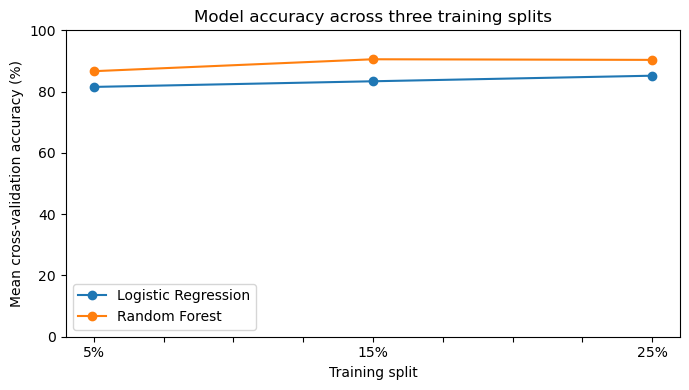

In [40]:
import matplotlib.pyplot as plt

ax = cv_summary.plot(
    x="Training split",
    y=[
        "Logistic Regression CV accuracy (%)",
        "Random Forest CV accuracy (%)"
    ],
    marker="o",
    figsize=(7, 4)
)

ax.set_title("Model accuracy across three training splits")
ax.set_xlabel("Training split")
ax.set_ylabel("Mean cross-validation accuracy (%)")
ax.set_ylim(0, 100)
ax.legend(["Logistic Regression", "Random Forest"])
plt.tight_layout()
plt.show()

In [41]:
from sklearn.model_selection import GridSearchCV

logistic_search = GridSearchCV(
    estimator=logistic_model,
    param_grid={"logisticregression__C": [0.1, 1, 10]},
    cv=folds_25,
    scoring="accuracy"
)

logistic_search.fit(X_train_25, y_train_25)

print("Best C:", logistic_search.best_params_["logisticregression__C"])
print(f"Best mean CV accuracy: {logistic_search.best_score_:.1%}")

Best C: 0.1
Best mean CV accuracy: 88.8%


In [42]:
forest_search = GridSearchCV(
    estimator=forest_model,
    param_grid={
        "n_estimators": [100, 200],
        "max_depth": [5, 10, None]
    },
    cv=folds_25,
    scoring="accuracy"
)

forest_search.fit(X_train_25, y_train_25)

print("Best parameters:", forest_search.best_params_)
print(f"Best mean CV accuracy: {forest_search.best_score_:.1%}")

Best parameters: {'max_depth': 5, 'n_estimators': 100}
Best mean CV accuracy: 90.4%


In [43]:
from sklearn.metrics import accuracy_score

logistic_predictions = logistic_search.best_estimator_.predict(X_test_25)
forest_predictions = forest_search.best_estimator_.predict(X_test_25)

logistic_test_accuracy = accuracy_score(y_test_25, logistic_predictions)
forest_test_accuracy = accuracy_score(y_test_25, forest_predictions)

print(f"Logistic Regression test accuracy: {logistic_test_accuracy:.1%}")
print(f"Random Forest test accuracy: {forest_test_accuracy:.1%}")

Logistic Regression test accuracy: 85.4%
Random Forest test accuracy: 84.9%


In [44]:
from sklearn.metrics import confusion_matrix

labels = ["Negative", "Positive"]

for name, predictions in [
    ("Logistic Regression", logistic_predictions),
    ("Random Forest", forest_predictions)
]:
    matrix = confusion_matrix(y_test_25, predictions, labels=labels)
    print(name)
    print(pd.DataFrame(
        matrix,
        index=["Actual Negative", "Actual Positive"],
        columns=["Predicted Negative", "Predicted Positive"]
    ))

Logistic Regression
                 Predicted Negative  Predicted Positive
Actual Negative                 128                  22
Actual Positive                  35                 205
Random Forest
                 Predicted Negative  Predicted Positive
Actual Negative                 121                  29
Actual Positive                  30                 210


In [45]:
logistic_train_accuracy = logistic_search.best_estimator_.score(X_train_25, y_train_25)
forest_train_accuracy = forest_search.best_estimator_.score(X_train_25, y_train_25)

print(f"Logistic Regression training accuracy: {logistic_train_accuracy:.1%}")
print(f"Random Forest training accuracy: {forest_train_accuracy:.1%}")

Logistic Regression training accuracy: 98.5%
Random Forest training accuracy: 99.2%


In [46]:
polyuria_summary = pd.crosstab(
    X_train_25["Polyuria"],
    y_train_25,
    normalize="index"
).mul(100).round(1)

print(polyuria_summary)

class     Negative  Positive
Polyuria                    
0             70.4      29.6
1              0.0     100.0


In [47]:
forest_importance = pd.Series(
    forest_search.best_estimator_.feature_importances_,
    index=X_train_25.columns,
    name="importance"
).sort_values(ascending=False)

print(forest_importance.round(3))

Polyuria              0.263
Polydipsia            0.200
sudden weight loss    0.114
Age                   0.084
Gender                0.060
Obesity               0.041
Genital thrush        0.033
weakness              0.031
partial paresis       0.025
Irritability          0.025
Polyphagia            0.023
muscle stiffness      0.022
Alopecia              0.022
delayed healing       0.021
visual blurring       0.020
Itching               0.016
Name: importance, dtype: float64


In [48]:
from sklearn.inspection import permutation_importance

permutation_result = permutation_importance(
    forest_search.best_estimator_,
    X_test_25,
    y_test_25,
    scoring="accuracy",
    n_repeats=20,
    random_state=42
)

polyuria_index = X_test_25.columns.get_loc("Polyuria")
mean_drop = permutation_result.importances_mean[polyuria_index]
std_drop = permutation_result.importances_std[polyuria_index]

print(f"Mean accuracy drop: {mean_drop * 100:.2f} percentage points")
print(f"Standard deviation: {std_drop * 100:.2f} percentage points")

Mean accuracy drop: 14.45 percentage points
Standard deviation: 1.69 percentage points


In [49]:
permutation_summary = pd.DataFrame({
    "Feature": X_test_25.columns,
    "Mean accuracy drop (pp)": permutation_result.importances_mean * 100,
    "Standard deviation (pp)": permutation_result.importances_std * 100
})

permutation_summary.sort_values(
    "Mean accuracy drop (pp)", ascending=False
).head(5).round(2)

,Feature,Mean accuracy drop (pp),Standard deviation (pp)
2,Polyuria,14.45,1.69
3,Polydipsia,11.32,1.64
10,Irritability,0.76,0.25
9,Itching,0.58,0.25
8,visual blurring,0.42,0.32


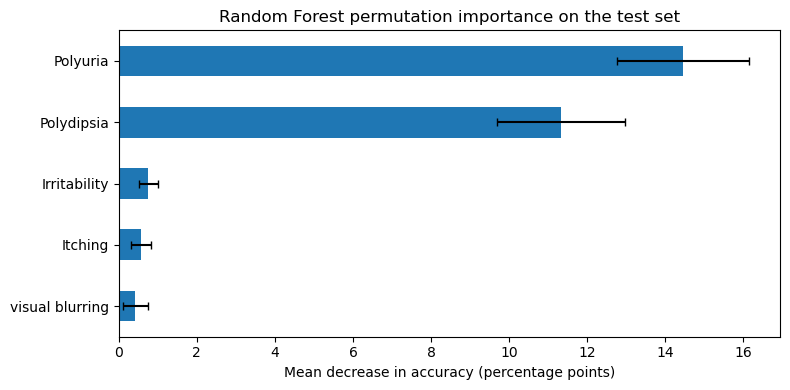

In [50]:
top_features = permutation_summary.nlargest(5, "Mean accuracy drop (pp)")
top_features = top_features.sort_values("Mean accuracy drop (pp)")

ax = top_features.plot.barh(
    x="Feature",
    y="Mean accuracy drop (pp)",
    xerr=top_features["Standard deviation (pp)"].to_numpy(),
    capsize=3,
    legend=False,
    figsize=(8, 4)
)

ax.set_title("Random Forest permutation importance on the test set")
ax.set_xlabel("Mean decrease in accuracy (percentage points)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()